# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- `FAST_MODE = True` - отладка на маленьком подмножестве, весь ноутбук не дольше 5 минут на T4. Финальный прогон - с `FAST_MODE = False`, ориентир до ~1 часа на T4. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются, даже если их ячейки пустые
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.**

**Укажите устройство**

Colab T4

**Выбранные модель и датасет (ссылка и лицензия)**

https://huggingface.co/cointegrated/rubert-tiny2
cointegrated/rubert-tiny2
лицензия MIT

https://huggingface.co/datasets/RCC-MSU/collection3
RCC-MSU/collection3
в лицензии написано Other

**бонусы**

{'6.1', '6.2', '6.3', '6.4', '6.5'}

**Ответ:**

In [1]:
# Зависимости (пины те же, что в requirements_nlp.txt). Запускайте эту ячейку первой, тогда перезапуск сессии не нужен
# Безвредный шум: строки ERROR от pip про bigframes / cudf / pyarrow на Kaggle и предупреждение про HF_TOKEN ниже (токен не нужен)
# Локально: сначала torch под свою платформу (https://pytorch.org/get-started/locally/)
%pip install -q "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [23]:
%pip install -q "seqeval==1.2.2"

In [24]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')   # одна GPU: на Kaggle T4 x2 иначе Trainer включит DataParallel (медленнее и хуже)
import collections
import copy
import json
import math
import random
import re
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(f'torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

torch 2.14.1+cu130, transformers 5.22.1, datasets 4.8.5
CUDA available: True


In [25]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else device.type
set_seed(0)
print(device, DEVICE_NAME)

cuda Tesla T4


In [6]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.1', '6.2', '6.3', '6.4', '6.5'}   # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
N_TRAIN = 2000 if FAST_MODE else None   # None - весь train
N_EVAL = 500 if FAST_MODE else None     # подмножество validation и test в FAST_MODE
EPOCHS = 1 if FAST_MODE else 3
MAX_LENGTH = 128                        # длина в сабвордах, длиннее - обрезается
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}

---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [7]:
MODEL_ID = 'cointegrated/rubert-tiny2'   # ваш код: id модели на Hugging Face Hub
REVISION = HfApi().model_info(MODEL_ID).sha   # ваш код: полный commit hash (40 символов)
TOKENIZER_KWARGS = {}   # для roberta-base: {'add_prefix_space': True}

In [8]:
assert MODEL_ID, 'укажите MODEL_ID'
assert re.fullmatch(r'[0-9a-f]{40}', REVISION or ''), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {s.rfilename: f'{s.size / 2**20:.0f} MB' for s in info.siblings if s.rfilename.endswith(('.safetensors', '.bin'))}
print(f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}')
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS)
assert tokenizer.is_fast, 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
print(tokenizer.tokenize('Петр Ильич Чайковский родился в Воткинске'))

model:    cointegrated/rubert-tiny2
revision: e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae
license:  mit
language: ['ru']
updated:  2025-12-30 08:33:24+00:00
weights:  {'model.safetensors': '112 MB', 'pytorch_model.bin': '112 MB'}


config.json:   0%|          | 0.00/693 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/401 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.08M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.74M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

BertTokenizer vocab size 83828
['Петр', 'Ильич', 'Чайк', '##овский', 'родился', 'в', 'Вот', '##кинс', '##ке']


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ:** Я выбрал rubert-tiny2:
* vocabulary: 83828 tokens;
* supported sequences: 2048;
* sentence embeddings approximate LaBSE
* meaningful segment embeddings (tuned on the NLI task)
* the model is focused only on Russian.
* Лицензия mit.
* Вообще я выбрал модель поменьше, чтобы быстрее все обучалось, плюс можно оценить, насколько хорошие результаты получаться.

rubert-base-cased (180M) и xlm-roberta-base (280M) в 6-10 раз больше и медленнее, но у них будет выигрыш по F1 около 3-4 процентов. XLM-R тратит часть словаря на другие языки.

Без фиксации revision через полгода могут перезалить веса, поменять токенизатор или конфиг, и результаты ноутбука перестанут воспроизводиться, а репозиторий вообще может исчезнуть.

## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [8]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS)
cfg = demo_model.config
print({k: getattr(cfg, k, None) for k in ['model_type', 'vocab_size', 'hidden_size', 'num_hidden_layers',
                                          'num_attention_heads', 'intermediate_size', 'max_position_embeddings']})
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

model.safetensors: reconstructing file:   0%|          |  0.00B /  118MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'model_type': 'bert', 'vocab_size': 83828, 'hidden_size': 312, 'num_hidden_layers': 3, 'num_attention_heads': 12, 'intermediate_size': 600, 'max_position_embeddings': 2048}
bert         BertModel
dropout      Dropout
classifier   Linear


In [9]:
def params_by_block(model):
    count = lambda m: sum(p.numel() for p in m.parameters())
    base = getattr(model, model.base_model_prefix)
    embeddings = count(base.embeddings)
    layers = [count(layer) for layer in base.encoder.layer]
    encoder = sum(layers)
    head = count(model.classifier)
    other = count(model) - embeddings - encoder - head
    return dict(embeddings=embeddings, encoder=encoder, head=head, other=other, layers=layers)

In [10]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert len(blocks['layers']) == cfg.num_hidden_layers and sum(blocks['layers']) == blocks['encoder'], \
    'encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other'
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings    26,794,560   92.1%
encoder        2,301,552    7.9%
head               2,191    0.0%
other                  0    0.0%
total         29,098,303
per layer: [767184, 767184, 767184]


In [14]:
demo_texts = [['Петр', 'Чайковский', 'родился', 'в', 'Воткинске', '.'],
              ['ITMO', 'University', 'is', 'in', 'Saint', 'Petersburg']]
enc = tokenizer(demo_texts, is_split_into_words=True, padding=True, return_tensors='pt')
demo_model.eval()
with torch.no_grad():
    out = demo_model(**enc, output_hidden_states=True)
print('input_ids', tuple(enc['input_ids'].shape))
print('attention_mask', tuple(enc['attention_mask'].shape))
for i, h in enumerate(out.hidden_states):
    print(f'hidden_states[{i}]', tuple(h.shape))
print('logits', tuple(out.logits.shape))

input_ids (2, 11)
attention_mask (2, 11)
hidden_states[0] (2, 11, 312)
hidden_states[1] (2, 11, 312)
hidden_states[2] (2, 11, 312)
hidden_states[3] (2, 11, 312)
logits (2, 11, 7)


In [15]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)

# скорость прямого прохода: батч 32 предложения x 62 слова (сколько это сабвордов - см. вывод)
x = {k: v.to(device) for k, v in tokenizer([['слово'] * 62] * 32, is_split_into_words=True, return_tensors='pt').items()}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
print(f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}')
demo_model = demo_model.cpu()

forward 32 x 64: 6.6 ms на Tesla T4


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ:**

'hidden_size': 312, 'num_hidden_layers': 3

1) input_ids (2, 11)
2) attention_mask (2, 11)
3) hidden_states[0] (2, 11, 312) embeddings
4) hidden_states[1] (2, 11, 312) encoder (3 слоя)
5) hidden_states[2] (2, 11, 312)
6) hidden_states[3] (2, 11, 312)
7) head
8) logits (2, 11, 7)

Больше всего параметров в embeddings 92%, потому что матрица эмбеддингов имеет размер примерно vocab_size на hidden_size и при большом словаре она больше.

Токены обмениваются информацией в encoder в self-attention. В embeddings и head каждый токен обрабатывается независимо.


T = 11 (слова + сабворды + CLS/SEP + паддинг до самого длинного предложения), изначальных слов 6.

---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [17]:
# пример формата на WikiANN ru (этот датасет брать нельзя)
example = load_dataset('unimelb-nlp/wikiann', 'ru', split='validation[:3]')
print(example)
print(example.features['ner_tags'].feature.names)
for ex in example:
    print(list(zip(ex['tokens'], ex['ner_tags'])), ex['spans'])

README.md:   0%|          | 0.00/158k [00:00<?, ?B/s]

ru/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  809kB            

ru/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

ru/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  816kB            

ru/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

ru/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.63MB            

ru/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating validation split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/20000 [00:00<?, ? examples/s]

Dataset({
    features: ['tokens', 'ner_tags', 'langs', 'spans'],
    num_rows: 3
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
[('Отличился', 0), ('во', 0), ('время', 0), ('боёв', 0), ('в', 0), ('Германии', 5), ('.', 0)] ['LOC: Германии']
[('1920—1922', 0), ('—', 0), ('техник', 0), ('военно-гидротехнического', 0), ('отряда', 0), ('(', 0), ('Чернигов', 5), (')', 0), (',', 0)] ['LOC: Чернигов']
[('Нагибин', 1), (',', 2), ('Владимир', 2), ('Владимирович', 2)] ['PER: Нагибин , Владимир Владимирович']


In [10]:
DATASET_ID, DATASET_CONFIG = 'RCC-MSU/collection3', None
raw = load_dataset(DATASET_ID, revision='refs/convert/parquet')
feat = raw['train'].features['ner_tags'].feature
LABEL_NAMES = list(feat.names) if hasattr(feat, 'names') else ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
print(raw)
print(LABEL_NAMES)

default/train/0000.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

default/train/0000.parquet: downloading bytes:           |  0.00B            

0000.parquet:   0%|          | 0.00/245k [00:00<?, ?B/s]

0000.parquet:   0%|          | 0.00/219k [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 9301
    })
    validation: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 2153
    })
    test: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 1922
    })
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']


In [18]:
# ваша статистика: сущности по типам и сплитам, длины спанов в словах, длины предложений
types = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})

def collect_stats(ds):
    ent = collections.Counter()
    lens = collections.defaultdict(list)
    for tags in ds['ner_tags']:
        names = [LABEL_NAMES[i] for i in tags]
        i = 0
        while i < len(names):
            if names[i].startswith('B-'):
                typ = names[i][2:]
                j = i + 1
                while j < len(names) and names[j] == 'I-' + typ:
                    j += 1
                ent[typ] += 1
                lens[typ].append(j - i)
                i = j
            else:
                i += 1
    return ent, lens

for split, ds in raw.items():
    ent, lens = collect_stats(ds)
    sent = np.array([len(t) for t in ds['tokens']])
    print(f'{split}: {len(ds)} предложений, слов в предложении: среднее {sent.mean():.1f}, медиана {np.median(sent):.0f}, p95 {np.percentile(sent, 95):.0f}, max {sent.max()}')
    for typ in types:
        l = np.array(lens[typ])
        print(f'  {typ}: {ent[typ]} сущностей, длина спана: среднее {l.mean():.2f}, 1 слово {np.mean(l == 1):.0%}, 2 слова {np.mean(l == 2):.0%}, 3+ слов {np.mean(l >= 3):.0%}, max {l.max()}')

train: 9301 предложений, слов в предложении: среднее 20.2, медиана 18, p95 41, max 256
  LOC: 4881 сущностей, длина спана: среднее 1.32, 1 слово 78%, 2 слова 16%, 3+ слов 7%, max 8
  ORG: 5956 сущностей, длина спана: среднее 2.00, 1 слово 54%, 2 слова 25%, 3+ слов 22%, max 18
  PER: 7405 сущностей, длина спана: среднее 2.01, 1 слово 27%, 2 слова 53%, 3+ слов 20%, max 10
validation: 2153 предложений, слов в предложении: среднее 20.4, медиана 18, p95 41, max 118
  LOC: 1168 сущностей, длина спана: среднее 1.30, 1 слово 79%, 2 слова 13%, 3+ слов 7%, max 6
  ORG: 1308 сущностей, длина спана: среднее 1.92, 1 слово 55%, 2 слова 24%, 3+ слов 21%, max 13
  PER: 1641 сущностей, длина спана: среднее 1.98, 1 слово 28%, 2 слова 53%, 3+ слов 18%, max 10
test: 1922 предложений, слов в предложении: среднее 20.9, медиана 19, p95 42, max 122
  LOC: 1175 сущностей, длина спана: среднее 1.28, 1 слово 80%, 2 слова 15%, 3+ слов 5%, max 8
  ORG: 1255 сущностей, длина спана: среднее 1.95, 1 слово 54%, 2 слов

**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ:**


Описание с сайта:


* Collection3 is a Russian dataset for named entity recognition annotated with LOC (location), PER (person), and ORG (organization) tags. Dataset is based on collection Persons-1000 originally containing 1000 news documents labeled only with names of persons.

* Additional labels were obtained using guidelines similar to MUC-7 with web-based tool Brat for collaborative text annotation.

* Currently dataset contains 26K annotated named entities (11K Persons, 7K Locations and 8K Organizations).

* Conversion to the IOB2 format and splitting into train, validation and test sets was done by DeepPavlov team.

Размеры: 9301 / 2153 / 1922 предложений, всего 26K сущностей: 11K PER, 8K ORG, 7K LOC. PER самый частый и в основном 2 слова (имя и фамилия), ORG самый разнообразный и с самыми длинными спанами (названия компаний, аббревиатуры), LOC в основном из 1 слова. Предложения новостные, в среднем 20 слов, редкие длинные хвосты.

На обучение может повлиять дисбаланс типов, ORG/LOC в теории могут пересекаться, разметка людьми с неизбежными расхождениями.

## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [11]:
def bio_to_spans(tags):
    spans, start, typ = [], None, None
    for i, tag in enumerate(tags):
        if tag == 'O':
            if start is not None:
                spans.append((start, i, typ))
                start, typ = None, None
            continue
        prefix, t = tag[0], tag[2:]
        if prefix == 'I' and start is not None and typ == t:
            continue
        if start is not None:
            spans.append((start, i, typ))
        start, typ = i, t
    if start is not None:
        spans.append((start, len(tags), typ))
    return spans


def spans_to_bio(spans, n_words):
    tags = ['O'] * n_words
    for start, end, typ in spans:
        tags[start] = 'B-' + typ
        for i in range(start + 1, end):
            tags[i] = 'I-' + typ
    return tags


def align_labels(word_labels, word_ids, b_to_i=None):
    labels, prev = [], None
    for w in word_ids:
        if w is None:
            labels.append(-100)
        elif w != prev:
            labels.append(word_labels[w])
        elif b_to_i is None:
            labels.append(-100)
        else:
            labels.append(b_to_i.get(word_labels[w], word_labels[w]))
        prev = w
    return labels

In [20]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [(0, 2, 'PER'), (3, 4, 'LOC'), (4, 6, 'LOC'), (7, 8, 'ORG')]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]       # I- без B- начинает спан
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [(0, 1, 'PER'), (1, 3, 'LOC')]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert bio_to_spans([]) == [] and bio_to_spans(['O'] * 3) == [] and spans_to_bio([], 2) == ['O', 'O']

rng = random.Random(0)
for _ in range(2000):   # туда-обратно на случайных спанах
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [-100, 1, -100, 0, 3, -100, -100, -100]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [-100, 1, 2, 0, 3, 4, 4, -100]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [-100, 2, 2, 6, -100]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]        # обрезка по MAX_LENGTH
print('ok')

ok


In [21]:
# если уже в BIO: экспорт в спаны JSON (data/<split>_spans.jsonl), чтение обратно, BIO, сравнение с исходным
Path('data').mkdir(exist_ok=True)
for split in raw:
    gold_tags = [[LABEL_NAMES[i] for i in ex['ner_tags']] for ex in raw[split]]
    with open(f'data/{split}_spans.jsonl', 'w', encoding='utf-8') as f:
        for ex, tags in zip(raw[split], gold_tags):
            f.write(json.dumps(dict(tokens=ex['tokens'], spans=bio_to_spans(tags)), ensure_ascii=False) + '\n')
    n_same = n_diff = 0
    with open(f'data/{split}_spans.jsonl', encoding='utf-8') as f:
        for line, tags in zip(f, gold_tags):
            rec = json.loads(line)
            spans = [tuple(s) for s in rec['spans']]
            back = spans_to_bio(spans, len(rec['tokens']))
            assert bio_to_spans(back) == bio_to_spans(tags)
            if back == tags:
                n_same += 1
            else:
                n_diff += 1
    print(f'{split}: BIO совпал в {n_same}, отличается (но спаны те же) в {n_diff}')

train: BIO совпал дословно в 9296, отличается (но спаны те же) в 5
validation: BIO совпал дословно в 2153, отличается (но спаны те же) в 0
test: BIO совпал дословно в 1921, отличается (но спаны те же) в 1


In [13]:
assert isinstance(raw, DatasetDict) and isinstance(LABEL_NAMES, list), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(raw), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {label2id[t]: label2id['I-' + t[2:]] for t in LABEL_NAMES if t.startswith('B-') and 'I-' + t[2:] in label2id}


def subset(ds, n):
    return ds if n is None else ds.shuffle(seed=SEED).select(range(min(n, len(ds))))


data = DatasetDict(train=subset(raw['train'], N_TRAIN), validation=subset(raw['validation'], N_EVAL),
                   test=subset(raw['test'], N_EVAL))


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    enc['labels'] = [align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
                     for i, tags in enumerate(batch['ner_tags'])]
    return enc


tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)

# проверка на реальных данных: метки первых сабвордов восстанавливают метки слов, спаны совпадают
n_truncated = n_lost_words = n_checked = 0
for ex in data['train']:
    enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    ids = enc.word_ids()
    labels = align_labels(ex['ner_tags'], ids)
    got = {w: l for w, l in zip(ids, labels) if l != -100}
    assert got == {w: ex['ner_tags'][w] for w in set(ids) - {None}}
    n_truncated += len(enc['input_ids']) == MAX_LENGTH
    n_lost = len(ex['tokens']) - len(got)
    n_lost_words += n_lost
    if n_lost == 0:
        back = [LABEL_NAMES[got[w]] for w in range(len(ex['tokens']))]
        assert bio_to_spans(back) == bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
        n_checked += 1
print(f'train: проверено {n_checked} предложений, обрезано по MAX_LENGTH {n_truncated}, слов без сабвордов или за обрезкой {n_lost_words}')

ex = data['train'][0]
enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(enc.tokens(), enc.word_ids(), align_labels(ex['ner_tags'], enc.word_ids())):
    print(f'{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}')

Map:   0%|          | 0/9301 [00:00<?, ? examples/s]

Map:   0%|          | 0/2153 [00:00<?, ? examples/s]

Map:   0%|          | 0/1922 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 9301
    })
    validation: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 2153
    })
    test: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 1922
    })
})
ENTITY_TYPES ['LOC', 'ORG', 'PER']
train: проверено 9288 предложений, обрезано по MAX_LENGTH 10, слов без сабвордов или за обрезкой 434
[CLS]            None  -100
До                  0  O
##полнение          0  -100
:                   1  O
Д                   2  B-PER
.                   3  I-PER
Медведев            4  I-PER
присвоил            5  O
звания              6  O
сотрудников         7  O
полиции             8  O
и                   9  O
перена             10  O
##зна              10  -100
##чил              10  -100
14                 11  O
руководителей      12  O
УВД                13  B-ORG
,                  14  O
ГУВД               15  B-ORG
и             

**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ:**

Метка ставится только на первый сабворд, чтобы у слова была ровно одна метка и оценка шла по словам, -100 это ignore_index у cross-entropy, такие позиции не входят в loss и не дают градиента.

По MAX_LENGTH = 128 обрезано 10 предложений из 23K, слов 434, на метрике это скажется на тысячных долях.

Collection3 уже в формате слов + BIO, а предложения новостные и короткие.
Проблем при конвертации нет, кроме 6 несошедшихся предложений, но с правильными спанами. Вложенных и пересекающихся спанов тут быть не может из-за BIO.

---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [14]:
@torch.no_grad()
def predict_word_tags(model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None):
    # теги слов по первому сабворду; слова без сабвордов или за MAX_LENGTH получают 'O' (вероятность 1)
    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        probs = model(**{k: v.to(dev) for k, v in enc.items()}).logits.float().softmax(-1).cpu()
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = ['O'] * len(words), [1.0] * len(words), set()
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
                f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
                precision=precision_score(gold, pred, zero_division=0),
                recall=recall_score(gold, pred, zero_division=0))


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID, revision=revision or REVISION,
        num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id)


val_tokens = [list(ws) for ws in data['validation']['tokens']]
val_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['validation']['ner_tags']]

In [15]:
def fit_majority_tagger(tokens_list, tags_list):
    counts = collections.defaultdict(collections.Counter)
    for words, tags in zip(tokens_list, tags_list):
        for w, t in zip(words, tags):
            counts[w][t] += 1
    return {w: c.most_common(1)[0][0] for w, c in counts.items()}


def predict_majority(tagger, words):
    return [tagger.get(w, 'O') for w in words]

In [25]:
toy_tokens = [['Анна', 'живет', 'в', 'Москве'], ['Москве', 'не', 'до', 'сна'], ['Анна', 'Каренина'], ['в', 'Москве']]
toy_tags = [['B-PER', 'O', 'O', 'B-LOC'], ['B-LOC', 'O', 'O', 'O'], ['B-PER', 'I-PER'], ['O', 'B-ORG']]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert toy['Москве'] == 'B-LOC' and toy['Анна'] == 'B-PER' and toy['Каренина'] == 'I-PER'
assert fit_majority_tagger([['Ленина']] * 4, [['B-LOC'], ['B-PER'], ['B-PER'], ['B-ORG']])['Ленина'] == 'B-PER'   # самый частый тег, а не первый или последний
assert predict_majority(toy, ['Анна', 'из', 'Москве']) == ['B-PER', 'O', 'B-LOC']
assert predict_majority(toy, []) == []

train_tokens = [list(ws) for ws in data['train']['tokens']]
train_tags = [[LABEL_NAMES[i] for i in tags] for tags in data['train']['ner_tags']]
tagger = fit_majority_tagger(train_tokens, train_tags)
baseline = {}
baseline['majority'] = entity_scores(val_gold, [predict_majority(tagger, ws) for ws in val_tokens])

set_seed(SEED)
random_model = make_model()
random_pred = predict_word_tags(random_model, val_tokens)
baseline['random_head'] = entity_scores(val_gold, random_pred)
del random_model
for name, scores in baseline.items():
    print(name, {k: round(v, 4) for k, v in scores.items()})
print('теги, которые предсказала случайная голова:', collections.Counter(t for tags in random_pred for t in tags).most_common(4))

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

majority {'f1_micro': np.float64(0.5613), 'f1_macro': np.float64(0.5786), 'precision': np.float64(0.5626), 'recall': np.float64(0.5601)}
random_head {'f1_micro': np.float64(0.0381), 'f1_macro': np.float64(0.0353), 'precision': np.float64(0.0223), 'recall': np.float64(0.1304)}
теги, которые предсказала случайная голова: [('O', 11544), ('I-PER', 11459), ('B-PER', 8688), ('I-LOC', 4833)]


**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ:**

У бейзлайна F1 = 0.56. Известные имена и страны из train он узнает (они могут повторятся в новостях), но новые фамилии и организации получают O, а также могут быть проблемы с путаньем классов.

У энкодера со случайной головой F1 = 0.038, почти ноль. Linear инициализирован случайно и не знает, какому признаку соответствует какой тег, поэтому предсказывает почти шум, и совпасть границы и тип целого спана практически не могут. Предобученные признаки в энкодере есть, но без обучения головы их не прочитать.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [16]:
LR = 2e-4          # подобрано под rubert-tiny2; у base-моделей обычно 2e-5 - 5e-5, выберите под свою модель
BATCH_SIZE = 32    # уменьшите, если не влезает в память T4


def train_ner(model, train_ds, eval_ds, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, freeze_encoder=False,
              tok=None, out_dir='runs/main'):
    # -> (history, seconds); history - список dict со 'step' и 'loss' или 'eval_loss'
    tok = tok or tokenizer
    if freeze_encoder:
        for name, p in model.named_parameters():
            p.requires_grad = name.startswith('classifier')
    total_steps = math.ceil(len(train_ds) / batch_size) * epochs
    eval_steps = max(1, total_steps // 10)
    args = TrainingArguments(
        output_dir=out_dir, num_train_epochs=epochs, learning_rate=lr,
        per_device_train_batch_size=batch_size, per_device_eval_batch_size=64,
        weight_decay=0.01, warmup_steps=int(0.1 * total_steps),
        eval_strategy='steps', eval_steps=eval_steps, logging_strategy='steps', logging_steps=eval_steps,
        save_strategy='no', fp16=torch.cuda.is_available(), report_to='none', seed=SEED)
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
                      data_collator=DataCollatorForTokenClassification(tok), processing_class=tok)
    start = time.perf_counter()
    trainer.train()
    seconds = time.perf_counter() - start
    return trainer.state.log_history, seconds

model.safetensors: reconstructing file:   0%|          |  0.00B /  118MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'loss': '0.7', 'grad_norm': '1.03', 'learning_rate': '0.0001977', 'epoch': '0.299'}
{'eval_loss': '0.1322', 'eval_runtime': '0.593', 'eval_samples_per_second': '3631', 'eval_steps_per_second': '57.34', 'epoch': '0.299'}
{'loss': '0.1167', 'grad_norm': '1.604', 'learning_rate': '0.0001781', 'epoch': '0.5979'}
{'eval_loss': '0.07133', 'eval_runtime': '0.5831', 'eval_samples_per_second': '3692', 'eval_steps_per_second': '58.3', 'epoch': '0.5979'}
{'loss': '0.08005', 'grad_norm': '0.7209', 'learning_rate': '0.000156', 'epoch': '0.8969'}
{'eval_loss': '0.05582', 'eval_runtime': '0.8655', 'eval_samples_per_second': '2488', 'eval_steps_per_second': '39.28', 'epoch': '0.8969'}
{'loss': '0.04767', 'grad_norm': '0.7111', 'learning_rate': '0.0001338', 'epoch': '1.196'}
{'eval_loss': '0.04963', 'eval_runtime': '0.5638', 'eval_samples_per_second': '3819', 'eval_steps_per_second': '60.31', 'epoch': '1.196'}
{'loss': '0.04318', 'grad_norm': '0.8303', 'learning_rate': '0.0001117', 'epoch': '1.495'}
{

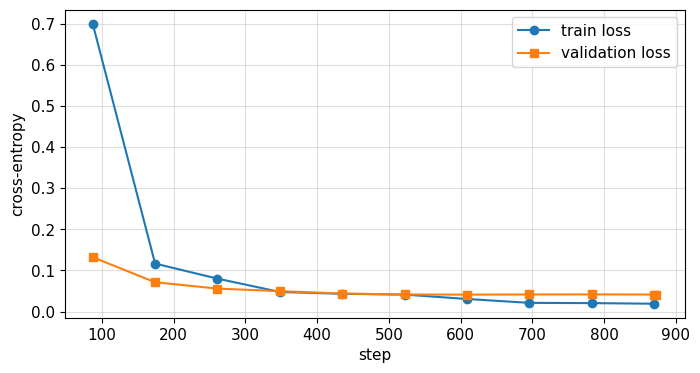

In [17]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized['train'], tokenized['validation'])
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert len(train_curve) >= 2 and len(eval_curve) >= 2, 'логируйте train и eval loss по ходу обучения'
print(f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)')

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ:**

Гиперпараметры: lr 2e-4 (для такой маленькой модели нужен большой шаг), batch 32 вообще на занял места, warmup 10% шагов, стандарный weight decay 0.01, fp16 для скорости, 3 эпохи при полном прогоне.

train loss мгновенно падает с 0.7 до 0.05 и дальше медленно, validation loss сначала меньше, но очень медленно уменьшается с 0.5 до 0.4 и train loss его обгоняет.

validation loss до последней эпохи падает, train loss не сильно опережает его, переобучения нет.

обучение: 36.7 c на Tesla T4

## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [18]:
def token_f1(gold, pred):
    tp = n_gold = n_pred = 0
    for g, p in zip(gold, pred):
        for a, b in zip(g, p):
            n_gold += a != 'O'
            n_pred += b != 'O'
            tp += a == b and a != 'O'
    if tp == 0:
        return 0.0
    precision, recall = tp / n_pred, tp / n_gold
    return 2 * precision * recall / (precision + recall)

In [20]:
g, p = [['B-PER', 'I-PER', 'O', 'B-LOC']], [['B-PER', 'O', 'O', 'B-LOC']]
assert abs(token_f1(g, p) - 0.8) < 1e-9                       # 2 верных слова из 2 предсказанных и 3 истинных
assert abs(f1_score(g, p) - 0.5) < 1e-9                       # а по сущностям верна одна из двух
assert token_f1([['O', 'O']], [['O', 'O']]) == 0.0 and token_f1(g, g) == 1.0

val_pred = predict_word_tags(model, val_tokens)
test_tokens = [list(ws) for ws in data['test']['tokens']]
test_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['test']['ner_tags']]
test_pred = predict_word_tags(model, test_tokens)

print('VALIDATION')
print(classification_report(val_gold, val_pred, digits=4, zero_division=0))
print({k: round(v, 4) for k, v in entity_scores(val_gold, val_pred).items()}, 'token_f1', round(token_f1(val_gold, val_pred), 4))
print('TEST')
print(classification_report(test_gold, test_pred, digits=4, zero_division=0))

report = classification_report(test_gold, test_pred, output_dict=True, zero_division=0)
final = dict(entity_scores(test_gold, test_pred))
final['token_f1'] = token_f1(test_gold, test_pred)
final['per_type'] = {t: report[t] for t in ENTITY_TYPES}
print({k: round(v, 4) for k, v in final.items() if k != 'per_type'})

VALIDATION
              precision    recall  f1-score   support

         LOC     0.9524    0.9426    0.9475      1168
         ORG     0.8350    0.8899    0.8616      1308
         PER     0.9612    0.9817    0.9714      1641

   micro avg     0.9172    0.9415    0.9292      4117
   macro avg     0.9162    0.9381    0.9268      4117
weighted avg     0.9186    0.9415    0.9297      4117

{'f1_micro': np.float64(0.9292), 'f1_macro': np.float64(0.9268), 'precision': np.float64(0.9172), 'recall': np.float64(0.9415)} token_f1 0.953
TEST
              precision    recall  f1-score   support

         LOC     0.9459    0.9515    0.9487      1175
         ORG     0.8452    0.8782    0.8614      1256
         PER     0.9597    0.9847    0.9720      1570

   micro avg     0.9192    0.9415    0.9302      4001
   macro avg     0.9169    0.9381    0.9274      4001
weighted avg     0.9197    0.9415    0.9304      4001

{'f1_micro': np.float64(0.9302), 'f1_macro': np.float64(0.9274), 'precision': n

**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ:**

Хуже всего ORG 0.81 по сравнению с 0.95 у других, потому что наиболее разнообразные названия и многословные спаны с хрупкими границами.

Micro F1 взвешен частотой типов, macro считает типы поровну, поэтому macro ниже micro из-за ORG, но разница небольшая, потому что редких типов тут нет.

Токенный F1 выше F1 по сущностям на 0.025, частично верный спан дает токенам очки, а по сущностям это ноль. Пользователю обычно нужна целая сущность с верными границами, поэтому F1 по сущностям ближе к реальности.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [32]:
ERROR_CATEGORIES = ['correct', 'boundary', 'type', 'missed', 'spurious']


def overlaps(a, b):
    return a[0] < b[1] and b[0] < a[1]


def categorize_errors(gold_spans, pred_spans):
    result = []
    for g in gold_spans:
        if g in pred_spans:
            result.append(('correct', g, g))
            continue
        over = [p for p in pred_spans if overlaps(g, p)]
        same_type = [p for p in over if p[2] == g[2]]
        if same_type:
            result.append(('boundary', g, same_type[0]))
        elif over:
            result.append(('type', g, over[0]))
        else:
            result.append(('missed', g, None))
    for p in pred_spans:
        if not any(overlaps(p, g) for g in gold_spans):
            result.append(('spurious', None, p))
    return result

In [34]:
gold = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 9, 'ORG'), (11, 12, 'PER')]
pred = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 9, 'LOC'), (13, 14, 'ORG')]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {'correct': 1, 'boundary': 1, 'type': 1, 'missed': 1, 'spurious': 1}
assert ('type', (7, 9, 'ORG'), (7, 9, 'LOC')) in res and ('spurious', None, (13, 14, 'ORG')) in res
assert ('boundary', (4, 5, 'LOC'), (4, 6, 'LOC')) in res and ('missed', (11, 12, 'PER'), None) in res
assert categorize_errors([], []) == [] and categorize_errors([], [(0, 1, 'PER')]) == [('spurious', None, (0, 1, 'PER'))]
assert [c for c, _, _ in categorize_errors([(0, 3, 'LOC')], [(1, 2, 'PER'), (2, 3, 'LOC')])] == ['boundary']
assert [c for c, _, _ in categorize_errors([(0, 2, 'LOC'), (2, 4, 'LOC')], [(0, 4, 'LOC')])] == ['boundary', 'boundary']
assert sorted(c for c, _, _ in categorize_errors([(0, 2, 'PER')], [(2, 3, 'PER')])) == ['missed', 'spurious']   # end не включается: спаны только соприкасаются

counter = collections.Counter({c: 0 for c in ERROR_CATEGORIES})
examples = collections.defaultdict(list)
for words, g, p in zip(val_tokens, val_gold, val_pred):
    for cat, gs, ps in categorize_errors(bio_to_spans(g), bio_to_spans(p)):
        counter[cat] += 1
        if cat != 'correct' and len(examples[cat]) < 5:
            examples[cat].append((words, gs, ps))
errors = {c: counter[c] for c in ERROR_CATEGORIES}
n_err = sum(v for c, v in errors.items() if c != 'correct')
for c in ERROR_CATEGORIES:
    share = f'{errors[c] / n_err:.1%} ошибок' if c != 'correct' else ''
    print(f'{c:<10}{errors[c]:>6}  {share}')

show = lambda words, s: None if s is None else f'{" ".join(words[s[0]:s[1]])} [{s[2]}]'
for cat, items in examples.items():
    for words, gs, ps in items:
        print(f'\n{cat}: {" ".join(words)[:200]}')
        print('  gold:', show(words, gs), '| pred:', show(words, ps))

correct     3883  
boundary     158  45.7% ошибок
type          52  15.0% ошибок
missed        24  6.9% ошибок
spurious     112  32.4% ошибок

spurious: Американскую дипмиссию в Тбилиси предложено возглавить Джону Бассу ( John R . Bass ) .
  gold: None | pred: Американскую [ORG]

spurious: После армии стал редактором костромской областной молодежной газеты " Молодежная линия " , затем возглавил Костромскую государственную телерадиокомпанию .
  gold: None | pred: молодежной [ORG]

spurious: В 2008г . назначен замруководителя Россвязькомнадзора , а уже в конце года стал руководителем Федеральной службы по надзору в сфере связи , информационных технологий и массовых коммуникаций .
  gold: None | pred: информационных технологий и массовых коммуникаций [ORG]

spurious: Адвокат коллегии " Трунов , Айвар и партнеры " Людмилы Айвар : " Уголовной ответственности не наступит , поскольку , когда какое - то заявление поступает по электронной почте , его должны проверять — 
  gold: None | pred: отв

**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ:**

Самая частая ошибочная категория boundary 46%, затем spurious 32%, потом missed 15%, type самая редкая 7%.

В boundary длинные ORG и PER с уточнениями, лишние или недостающие символы

В type - локация как организация, организации названные именами людей,сложные уникальные абривеатуры

missed и spurious сложные сокращения и абривеатуры, где смысловой контекст токена подсказывает, что там что то должно быть, но модель либо не встречала такого, либо слишком зациклилась.

Чтобы уменьшить boundary нужно больше эпох или более крупная модель, более разнообразные примеры разметки (больше данных), здесь еще не проявились какие-то архитектурные проблемы.

## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

In [35]:
ABLATION = 'freeze'   # 'freeze' или 'all_subwords'
ablation = {}

set_seed(SEED)
frozen_model = make_model()
_, frozen_seconds = train_ner(frozen_model, tokenized['train'], tokenized['validation'], freeze_encoder=True, out_dir='runs/freeze')
frozen_pred = predict_word_tags(frozen_model, val_tokens)
ablation = dict(
    setting='freeze',
    full=dict(entity_scores(val_gold, val_pred), seconds=RUN_TIMES['train_main_sec'],
              trainable_params=sum(p.numel() for p in model.parameters() if p.requires_grad)),
    frozen=dict(entity_scores(val_gold, frozen_pred), seconds=frozen_seconds,
                trainable_params=sum(p.numel() for p in frozen_model.parameters() if p.requires_grad)))
for name in ['full', 'frozen']:
    a = ablation[name]
    print(f'{name:<7} F1 micro {a["f1_micro"]:.4f}  macro {a["f1_macro"]:.4f}  время {a["seconds"]:.1f} c  обучаемых параметров {a["trainable_params"]:,}')

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'loss': '1.585', 'grad_norm': '2.769', 'learning_rate': '0.0001977', 'epoch': '0.299'}
{'eval_loss': '1.082', 'eval_runtime': '0.8281', 'eval_samples_per_second': '2600', 'eval_steps_per_second': '41.06', 'epoch': '0.299'}
{'loss': '0.7553', 'grad_norm': '0.7191', 'learning_rate': '0.0001781', 'epoch': '0.5979'}
{'eval_loss': '0.5248', 'eval_runtime': '0.9864', 'eval_samples_per_second': '2183', 'eval_steps_per_second': '34.47', 'epoch': '0.5979'}
{'loss': '0.4995', 'grad_norm': '0.5029', 'learning_rate': '0.000156', 'epoch': '0.8969'}
{'eval_loss': '0.3987', 'eval_runtime': '1.534', 'eval_samples_per_second': '1404', 'eval_steps_per_second': '22.17', 'epoch': '0.8969'}
{'loss': '0.4075', 'grad_norm': '0.4221', 'learning_rate': '0.0001338', 'epoch': '1.196'}
{'eval_loss': '0.3419', 'eval_runtime': '0.9079', 'eval_samples_per_second': '2372', 'eval_steps_per_second': '37.45', 'epoch': '1.196'}
{'loss': '0.3714', 'grad_norm': '0.4203', 'learning_rate': '0.0001117', 'epoch': '1.495'}
{'e

**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

**Ответ:**

Сильное падение F1 при заморозке с 0.9 до 0.6. Замороженный предобученный энкодер дает универсальные признаки, а линейной головы не хватает, чтобы выделять границы спанов по ним, к тому же lr и число шагов не подбирались под заморозку. Время упало на 4 сек, потому что прямой проход через энкодер остается, экономится только обратный.

Далее можно проверить несколько seed, более высокий lr и частичную разморозку верхнего слоя, чтобы понять, что вклад дают именно признаки энкодера, а не плохо подобранные параметры.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ:**

Бейзлайн дал F1 = 0.56, дообученный rubert-tiny2 на test дал F1 по сущностям = 0.93 за 30 сек обучения, то есть дообучение дает +37 процентов и стоит очень мало;

Слабее всего класс ORG с F1 = 0.84

Главная категория ошибок это boundary, часть из них - несогласованность разметки, а не модели

Заморозка энкодера роняет F1 почти до бейзлайна, значит полное дообучение здесь необходимо

Ограничения: маленькая модель с 29M параметров, новостной домен (на текстах другого стиля качество упадет), три типа сущностей, один seed, без подбора гиперпараметров.

Дальше можно сравнить с другими моделями, поиграться с гиперпараметрами, добавить обработку границ и проверку на других данных.

### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

In [36]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track='nlp', model=MODEL_ID, revision=REVISION,
    dataset=f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID), classes=ENTITY_TYPES,
    n_train=len(data['train']), n_val=len(data['validation']), n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline, final=final, ablation=ablation, errors=errors,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES.get('train_main_sec'), fast_mode=FAST_MODE)
for key in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1', 'per_type']:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(json_ready({k: v for k, v in metrics.items() if k not in ('final', 'baseline')}), ensure_ascii=False)[:600])
print('final F1 micro', round(final['f1_micro'], 4))

{"track": "nlp", "model": "cointegrated/rubert-tiny2", "revision": "e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae", "dataset": "RCC-MSU/collection3", "classes": ["LOC", "ORG", "PER"], "n_train": 9301, "n_val": 2153, "n_test": 1922, "params_total": 29098303, "ablation": {"setting": "freeze", "full": {"f1_micro": 0.9306171360095866, "f1_macro": 0.928201488074298, "precision": 0.9184011352885525, "recall": 0.9431624969638086, "seconds": 36.72036777999983, "trainable_params": 29098303}, "frozen": {"f1_micro": 0.6144443058500686, "f1_macro": 0.5960582694517299, "precision": 0.6315384615384615, "recall":
final F1 micro 0.9307


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

In [37]:
if '6.1' in BONUS_TASKS:
    from datasets import Dataset, concatenate_datasets

    EXTRA_TEXTS = [
        "[Игорь Сикорский|PER] основал в [США|LOC] компанию [Sikorsky Aircraft|ORG] .",
        "Вчера в [Казани|LOC] прошёл матч между [Рубином|ORG] и [Спартаком|ORG] .",
        "Премьер-министр [Михаил Мишустин|PER] провёл совещание с главой [Минфина|ORG] [Антоном Силуановым|PER] .",
        "Концерн « [Калашников|ORG] » увеличил выпуск гражданского оружия .",
        "Суд в [Екатеринбурге|LOC] отклонил иск компании « [Уралмаш|ORG] » к [Сбербанку|ORG] .",
        "Писатель [Виктор Пелевин|PER] живёт в [Москве|LOC] , а его книги издаёт [Эксмо|ORG] .",
        "Нападающий [Артём Дзюба|PER] забил гол в ворота [Зенита|ORG] .",
        "Учёные из [МГУ|ORG] и [РАН|ORG] открыли новый вид мха на [Камчатке|LOC] .",
        "Президент [Франции|LOC] [Эмманюэль Макрон|PER] прилетел в [Берлин|LOC] на переговоры .",
        "Компания [Яндекс|ORG] открыла новый офис в [Нижнем Новгороде|LOC] .",
        "Мэр [Сергей Собянин|PER] открыл новую станцию метро на юге [Москвы|LOC] .",
        "[Роспотребнадзор|ORG] проверил кафе в [Новосибирске|LOC] после жалоб посетителей .",
        "Режиссёр [Андрей Звягинцев|PER] представил новый фильм на фестивале в [Каннах|LOC] .",
        "Футболист [Лионель Месси|PER] перешёл из « [Барселоны|ORG] » в [ПСЖ|ORG] .",
        "Глава [Газпрома|ORG] [Алексей Миллер|PER] обсудил поставки газа в [Китай|LOC] .",
        "Река [Лена|LOC] протекает по территории [Якутии|LOC] .",
        "Сотрудники [МЧС|ORG] эвакуировали жителей посёлка под [Красноярском|LOC] .",
        "Блогер [Юрий Дудь|PER] выпустил интервью с основателем [ВКонтакте|ORG] [Павлом Дуровым|PER] .",
        "Агентство [Reuters|ORG] сообщает о визите делегации в [Анкару|LOC] .",
        "Актриса [Чулпан Хаматова|PER] основала фонд « [Подари жизнь|ORG] » .",
        "« [Новая газета|ORG] » опубликовала расследование о закупках в [Минобороны|ORG] .",
        "Депутаты [Госдумы|ORG] приняли закон в третьем чтении .",
        "Банк [ВТБ|ORG] повысил ставки по вкладам для жителей [Урала|LOC] .",
        "Альпинист [Денис Урубко|PER] покорил [Эверест|LOC] без кислорода .",
        "Хоккеисты [СКА|ORG] обыграли [ЦСКА|ORG] со счётом 3:1 .",
        "Учёный [Жорес Алфёров|PER] получил Нобелевскую премию за работы в [Физико-техническом институте|ORG] .",
        "Самолёт авиакомпании [Аэрофлот|ORG] вылетел из [Шереметьево|LOC] в [Сочи|LOC] .",
        "Лидер [Лейбористской партии|ORG] [Кир Стармер|PER] выступил в [Лондоне|LOC] .",
        "Писатель [Лев Толстой|PER] похоронен в [Ясной Поляне|LOC] .",
        "Корреспондент [ТАСС|ORG] [Мария Иванова|PER] передаёт из [Минска|LOC] .",
        "Инженеры [Роскосмоса|ORG] готовят запуск ракеты с космодрома [Восточный|LOC] .",
        "Тренер [Валерий Карпин|PER] возглавил сборную [России|LOC] .",
        "В [Томском политехническом университете|ORG] открылась новая лаборатория .",
        "Шеф-повар [Владимир Мухин|PER] открыл ресторан в [Сочи|LOC] .",
        "Рабочие завода « [Норильский никель|ORG] » потребовали повышения зарплат .",
        "Историк [Наталья Басовская|PER] выступила с лекцией в [Музее Москвы|ORG] .",
        "Власти [Крыма|LOC] запретили продажу алкоголя ночью .",
        "Компания [Apple|ORG] открыла магазин в [Дубае|LOC] .",
        "Хакеры взломали сайт [Министерства образования Украины|ORG] .",
        "Музыкант [Борис Гребенщиков|PER] выступил на фестивале в [Тбилиси|LOC] .",
        "Памятник [Борису Ельцину|PER] открыли в [Екатеринбурге|LOC] .",
        "[Сергей Лавров|PER] заявил , что [МИД|ORG] не получал приглашений от [Вашингтона|LOC] .",
        "Врачи [Боткинской больницы|ORG] спасли пациента с тяжёлой травмой .",
        "Пловец [Евгений Рылов|PER] завоевал золото на чемпионате в [Токио|LOC] .",
        "[Следственный комитет|ORG] возбудил дело против директора школы в [Рязани|LOC] .",
        "Фермеры [Краснодарского края|LOC] жалуются на засуху .",
        "Оператор [МТС|ORG] запустил связь 5G в [Казани|LOC] .",
        "Поэт [Иосиф Бродский|PER] эмигрировал в [США|LOC] в 1972 году .",
        "Игроки [Реала|ORG] вернулись в [Мадрид|LOC] после победы над [Манчестер Сити|ORG] .",
        "Мэр [Владивостока|LOC] [Константин Шестаков|PER] осмотрел новый мост .",
        "Пользователи [Телеграма|ORG] пожаловались на сбои .",
        "Адвокат [Генри Резник|PER] заявил в интервью « [Эху Москвы|ORG] » .",
        "Туристы из [Германии|LOC] и [Италии|LOC] приехали на [Байкал|LOC] .",
        "Композитор [Эннио Морриконе|PER] умер в [Риме|LOC] в 2020 году .",
        "Глава [РЖД|ORG] [Олег Белозёров|PER] рассказал о планах строительства дороги до [Мурманска|LOC] .",
        "Студенты [Высшей школы экономики|ORG] выиграли чемпионат по программированию .",
        "[Алла Пугачёва|PER] дала концерт в [Юрмале|LOC] .",
        "Аналитики [Goldman Sachs|ORG] ожидают роста цен на нефть .",
        "Вратарь [ЦСКА|ORG] [Игорь Акинфеев|PER] отразил пенальти .",
        "Депутат [Мосгордумы|ORG] [Евгений Бунимович|PER] предложил открыть библиотеку в [Зеленограде|LOC] .",
    ]

    def parse_markup(text):
        tokens, tags, pos = [], [], 0
        for m in re.finditer(r'\[([^|\]]+)\|(PER|ORG|LOC)\]', text):
            for w in text[pos:m.start()].split():
                tokens.append(w)
                tags.append('O')
            for k, w in enumerate(m.group(1).split()):
                tokens.append(w)
                tags.append(('B-' if k == 0 else 'I-') + m.group(2))
            pos = m.end()
        for w in text[pos:].split():
            tokens.append(w)
            tags.append('O')
        return tokens, tags

    extra = [parse_markup(t) for t in EXTRA_TEXTS]
    assert len(extra) >= 50
    Path('annotations').mkdir(exist_ok=True)
    with open('annotations/extra_spans.jsonl', 'w', encoding='utf-8') as f:
        for tokens, tags in extra:
            f.write(json.dumps(dict(tokens=tokens, spans=bio_to_spans(tags)), ensure_ascii=False) + '\n')

    extra_train, extra_test = extra[::2], extra[1::2]
    extra_train_ds = Dataset.from_dict(dict(tokens=[t for t, _ in extra_train],
                                            ner_tags=[[label2id[x] for x in tags] for _, tags in extra_train]))
    extra_train_tok = extra_train_ds.map(tokenize_and_align, batched=True, remove_columns=['tokens', 'ner_tags'])
    extra_test_tokens = [t for t, _ in extra_test]
    extra_test_gold = [tags for _, tags in extra_test]
    print(f'всего {len(extra)} предложений: {len(extra_train)} в train, {len(extra_test)} отложены в тест')
    print('сущностей в отложенном тесте:', sum(len(bio_to_spans(t)) for t in extra_test_gold))

    EXTRA_REPEAT = 10
    set_seed(SEED)
    model_extra = make_model()
    train_extra = concatenate_datasets([tokenized['train']] + [extra_train_tok] * EXTRA_REPEAT)
    train_ner(model_extra, train_extra, tokenized['validation'], out_dir='runs/extra')

    extra_results = {
        'before': dict(extra_test=entity_scores(extra_test_gold, predict_word_tags(model, extra_test_tokens)),
                       validation=entity_scores(val_gold, val_pred)),
        'after': dict(extra_test=entity_scores(extra_test_gold, predict_word_tags(model_extra, extra_test_tokens)),
                      validation=entity_scores(val_gold, predict_word_tags(model_extra, val_tokens)))}
    for stage, res in extra_results.items():
        for split, scores in res.items():
            print(f'{stage:<7}{split:<11}', {k: round(v, 4) for k, v in scores.items()})
    del model_extra
    torch.cuda.empty_cache()

Map:   0%|          | 0/30 [00:00<?, ? examples/s]

всего 60 предложений: 30 в train, 30 отложены в тест
сущностей в отложенном тесте: 64


Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'loss': '0.7022', 'grad_norm': '0.6867', 'learning_rate': '0.0001978', 'epoch': '0.299'}
{'eval_loss': '0.1278', 'eval_runtime': '1.986', 'eval_samples_per_second': '1084', 'eval_steps_per_second': '17.12', 'epoch': '0.299'}
{'loss': '0.1107', 'grad_norm': '1.292', 'learning_rate': '0.0001781', 'epoch': '0.598'}
{'eval_loss': '0.06227', 'eval_runtime': '1.566', 'eval_samples_per_second': '1375', 'eval_steps_per_second': '21.72', 'epoch': '0.598'}
{'loss': '0.07428', 'grad_norm': '3.122', 'learning_rate': '0.000156', 'epoch': '0.897'}
{'eval_loss': '0.05583', 'eval_runtime': '3.671', 'eval_samples_per_second': '586.5', 'eval_steps_per_second': '9.261', 'epoch': '0.897'}
{'loss': '0.0498', 'grad_norm': '0.3489', 'learning_rate': '0.0001338', 'epoch': '1.196'}
{'eval_loss': '0.04896', 'eval_runtime': '0.4947', 'eval_samples_per_second': '4352', 'eval_steps_per_second': '68.73', 'epoch': '1.196'}
{'loss': '0.0409', 'grad_norm': '1.5', 'learning_rate': '0.0001117', 'epoch': '1.495'}
{'eval

**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ:**

Я залил примеры где получились ошибки в llm и попросил сгенирировать похожие примеры: разметил 60 новых предложений из других источников и стилей (спорт, бизнес, культура, регионы, мировые новости) и возникших трудных случаев: аббревиатуры (МЧС, РЖД, ВТБ), организации в кавычках, клубы вместо городов (Барселона, Реал), латиница (Apple, Reuters, Goldman Sachs), длинные названия организаций.

половина 30 предложений с 55 сущностями ушли в train с повтором, вторая половина 30 предложений отложена как отдельный тест.

На отложенном тесте F1 на удивление довольно сильно упала, а на validation увеличилась почти на процент, то есть все равно это пошло на пользу модели.

Сомневаться можно в городах как организациях/мест [Вашингтона|LOC], в аэропорте [Шереметьево|LOC], музее и больнице как ORG/LOC.

## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [28]:
if '6.2' in BONUS_TASKS:
    ID2 = 'DeepPavlov/rubert-base-cased'
    REV2 = HfApi().model_info(ID2).sha
    tok2 = AutoTokenizer.from_pretrained(ID2, revision=REV2)
    assert tok2.is_fast
    tokenized2 = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names,
                          fn_kwargs=dict(tok=tok2))

    set_seed(SEED)
    model2 = make_model(ID2, REV2)
    _, seconds2 = train_ner(model2, tokenized2['train'], tokenized2['validation'], lr=5e-5, tok=tok2, out_dir='runs/base')

    def sync():
        if device.type == 'cuda':
            torch.cuda.synchronize()

    def timed_predict(m, tok, tokens):
        predict_word_tags(m, tokens[:64], tok=tok)
        sync()
        start = time.perf_counter()
        pred = predict_word_tags(m, tokens, tok=tok)
        sync()
        return pred, time.perf_counter() - start

    compare = {}
    for name, m, tok, train_sec in [('rubert-tiny2', model, tokenizer, RUN_TIMES['train_main_sec']),
                                    ('rubert-base-cased', model2, tok2, seconds2)]:
        pred_val, infer_sec = timed_predict(m, tok, val_tokens)
        pred_test = predict_word_tags(m, test_tokens, tok=tok)
        n_params = sum(p.numel() for p in m.parameters())
        compare[name] = dict(val_f1=f1_score(val_gold, pred_val), test_f1=f1_score(test_gold, pred_test),
                              train_sec=train_sec, infer_sec=infer_sec, params=n_params, size_mb=n_params * 4 / 2**20)
    for name, r in compare.items():
        print(f'{name:<18} val F1 {r["val_f1"]:.4f}  test F1 {r["test_f1"]:.4f}  обучение {r["train_sec"]:.0f} c  '
              f'инференс val {r["infer_sec"]:.2f} c  параметров {r["params"]:,}  {r["size_mb"]:.0f} MB')
    del model2
    torch.cuda.empty_cache()

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '0.5484', 'grad_norm': '1.352', 'learning_rate': '4.943e-05', 'epoch': '0.299'}
{'eval_loss': '0.03599', 'eval_runtime': '1.72', 'eval_samples_per_second': '1252', 'eval_steps_per_second': '19.77', 'epoch': '0.299'}
{'loss': '0.05099', 'grad_norm': '1.083', 'learning_rate': '4.453e-05', 'epoch': '0.5979'}
{'eval_loss': '0.02807', 'eval_runtime': '1.727', 'eval_samples_per_second': '1247', 'eval_steps_per_second': '19.69', 'epoch': '0.5979'}
{'loss': '0.03559', 'grad_norm': '0.402', 'learning_rate': '3.899e-05', 'epoch': '0.8969'}
{'eval_loss': '0.0233', 'eval_runtime': '1.734', 'eval_samples_per_second': '1241', 'eval_steps_per_second': '19.6', 'epoch': '0.8969'}
{'loss': '0.02508', 'grad_norm': '0.2322', 'learning_rate': '3.346e-05', 'epoch': '1.196'}
{'eval_loss': '0.02655', 'eval_runtime': '1.756', 'eval_samples_per_second': '1226', 'eval_steps_per_second': '19.37', 'epoch': '1.196'}
{'loss': '0.02281', 'grad_norm': '0.5895', 'learning_rate': '2.793e-05', 'epoch': '1.495'}


**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ:**


Сравнил rubert-tiny2 (29M) с rubert-base-cased (178M). rubert-base-cased лучше: 0.978 против 0.93 по F1 на test, то есть base лучше.

Цена: обучение 2 минуты вместо 33 секунд (в 4 раза больше), инференс на validation немного дольше, но это некритично, параметров в 6 раз больше, вес около 680 MB вместо 110 MB.

Честность за счет одних и тех же данных и разбиения, тот же seed, 3 эпохи, batch 32, warmup 10% и weight decay 0.01, fp16, метрика одна и та же (seqeval по словам). Различается только lr: 2e-4 у tiny и 5e-5 у base, потому что base с 2e-4 расходится, а у tiny 5e-5 недообучает.

## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

In [22]:
if '6.3' in BONUS_TASKS:
    print(tokenizer.tokenize('Москва МОСКВА москва'))

    def add_typos(tokens_list, p=0.15, seed=SEED):
        rng = random.Random(seed)
        out = []
        for words in tokens_list:
            new = []
            for w in words:
                if len(w) > 3 and w.isalpha() and rng.random() < p:
                    i = rng.randrange(len(w) - 1)
                    w = w[:i] + w[i + 1] + w[i] + w[i + 2:]
                new.append(w)
            out.append(new)
        return out

    TRANSLIT = dict(zip('абвгдеёжзийклмнопрстуфхцчшщъыьэюя',
                        ['a', 'b', 'v', 'g', 'd', 'e', 'yo', 'zh', 'z', 'i', 'y', 'k', 'l', 'm', 'n', 'o', 'p', 'r', 's',
                         't', 'u', 'f', 'kh', 'ts', 'ch', 'sh', 'shch', "'", 'y', "'", 'e', 'yu', 'ya']))

    def translit_word(w):
        out = ''
        for c in w:
            t = TRANSLIT.get(c.lower())
            out += c if t is None else (t.capitalize() if c.isupper() else t)
        return out

    corruptions = {
        'clean': lambda toks: toks,
        'typos': add_typos,
        'lower': lambda toks: [[w.lower() for w in ws] for ws in toks],
        'upper': lambda toks: [[w.upper() for w in ws] for ws in toks],
        'translit': lambda toks: [[translit_word(w) for w in ws] for ws in toks],
    }
    shift_results = {}
    for name, fn in corruptions.items():
        bad_tokens = fn(val_tokens)
        assert [len(a) for a in bad_tokens] == [len(a) for a in val_tokens]
        shift_results[name] = entity_scores(val_gold, predict_word_tags(model, bad_tokens))
        print(f'{name:<9} F1 micro {shift_results[name]["f1_micro"]:.4f}  macro {shift_results[name]["f1_macro"]:.4f}')
    print(' '.join(corruptions['typos'](val_tokens[:1])[0]))
    print(' '.join(corruptions['translit'](val_tokens[:1])[0]))

['Москва', 'МО', '##СК', '##ВА', 'мос', '##ква']
clean     F1 micro 0.9292  macro 0.9268
typos     F1 micro 0.8813  macro 0.8797
lower     F1 micro 0.0477  macro 0.0425
upper     F1 micro 0.0703  macro 0.0796
translit  F1 micro 0.1166  macro 0.1220
Обама назначил послов США в Грузии и Таджикистане
Obama naznachil poslov SShA v Gruzii i Tadzhikistane


**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ:**

Сильнее всего F1 роняет lower 0.047, она полностью убирает главный признак сущности — заглавные буквы, на который модель почти целиком опирается. Токенизатор модели чувствителен к регистру, поэтому после lower слова превращаются в редкие/незнакомые токены и режутся иначе, чем в обучении. upper роняет чуть меньше 0.07, но эффект как у lower. translit сохраняет паттерн заглавных букв, но так как модель русская, то она все равно не справляется, хотя удивительно, что регистр сильнее чем язык. typos почти не мешают.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [26]:
if '6.4' in BONUS_TASKS:
    import io

    cpu = torch.device('cpu')
    fp32_model = copy.deepcopy(model).cpu().eval()
    int8_model = torch.ao.quantization.quantize_dynamic(fp32_model, {torch.nn.Linear}, dtype=torch.qint8)
    batch = tokenizer(val_tokens[:32], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH,
                      padding=True, return_tensors='pt')

    def latency_ms(m, runs=20):
        with torch.inference_mode():
            for _ in range(3):
                m(**batch)
            start = time.perf_counter()
            for _ in range(runs):
                m(**batch)
        return (time.perf_counter() - start) / runs * 1000

    def size_mb(m):
        buf = io.BytesIO()
        torch.save(m.state_dict(), buf)
        return buf.getbuffer().nbytes / 2**20

    speed_results = {}
    for name, m in [('fp32', fp32_model), ('int8', int8_model)]:
        pred = predict_word_tags(m, val_tokens, dev=cpu)
        speed_results[name] = dict(latency_ms=latency_ms(m), size_mb=size_mb(m), **entity_scores(val_gold, pred))
        r = speed_results[name]
        print(f'{name:<5} батч {tuple(batch["input_ids"].shape)} на CPU: {r["latency_ms"]:.1f} мс  размер {r["size_mb"]:.0f} MB  '
              f'F1 micro {r["f1_micro"]:.4f}')
    print(f'ускорение x{speed_results["fp32"]["latency_ms"] / speed_results["int8"]["latency_ms"]:.2f}')

/tmp/ipykernel_186/3056121838.py:6: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  int8_model = torch.ao.quantization.quantize_dynamic(fp32_model, {torch.nn.Linear}, dtype=torch.qint8)
/usr/local/lib/python3.13/dist-packages/torch/ao/nn/quantized/modules/utils.py:72: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation fun

fp32  батч (32, 48) на CPU: 409.5 мс  размер 111 MB  F1 micro 0.9292
int8  батч (32, 48) на CPU: 204.0 мс  размер 104 MB  F1 micro 0.9296
ускорение x2.01


**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ:**

Использовал int8-квантизацию линейных слоев на CPU Colab, замер на одном батче из 32 предложений, прогрев 3 запуска, среднее по 20.

Ускорение в 2 раза, f1 micro поменялось на 0.0004, что в пределах шума. Размер файла падает около 10%.

Выигрыш зависит от модели, потому что у rubert-tiny2 90% параметров лежат в таблице эмбеддингов, а она не квантуется и вообще не считает матричные умножения. Вычисления идут в 3 слоях энкодера с hidden 312, их линейные слои и ускоряет int8, но они и так маленькие, а накладные расходы на квантизацию-деквантизацию активаций сравнимы с самим умножением. Чем больше вычислений в модели, тем больше выигрыш.

## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

порог 0: F1 0.9292 | seqeval F1 0.9292
mean  лучший порог 0.81: P 0.9458 R 0.9286 F1 0.9371 (при пороге 0: 0.9292, прирост +0.0080)
min   лучший порог 0.76: P 0.9491 R 0.9240 F1 0.9364 (при пороге 0: 0.9292, прирост +0.0072)


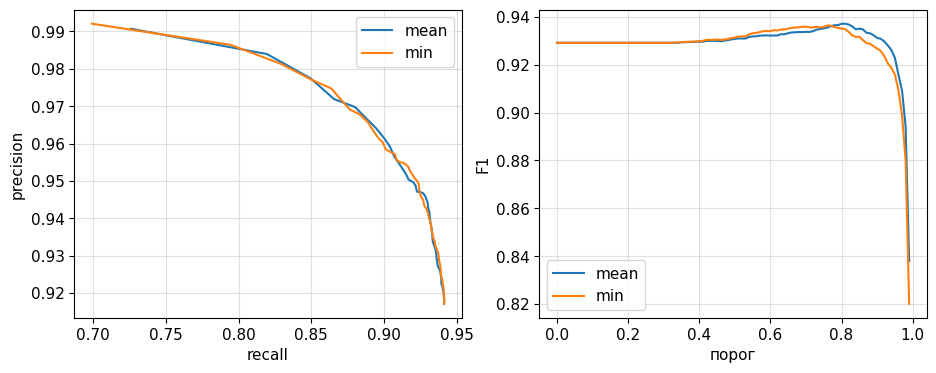

In [27]:
if '6.5' in BONUS_TASKS:
    conf_tags, conf_probs = predict_word_tags(model, val_tokens, return_probs=True)
    gold_spans = [set(bio_to_spans(g)) for g in val_gold]
    pred_spans = [[(s, e, t, float(np.mean(p[s:e])), float(np.min(p[s:e]))) for s, e, t in bio_to_spans(tags)]
                  for tags, p in zip(conf_tags, conf_probs)]
    n_gold = sum(len(g) for g in gold_spans)

    def scores_at(threshold, k):
        tp = n_pred = 0
        for gold, preds in zip(gold_spans, pred_spans):
            kept = {sp[:3] for sp in preds if sp[k] >= threshold}
            n_pred += len(kept)
            tp += len(kept & gold)
        precision = tp / n_pred if n_pred else 0.0
        recall = tp / n_gold
        f1 = 2 * precision * recall / (precision + recall) if tp else 0.0
        return precision, recall, f1

    thresholds = np.round(np.arange(0, 1.0, 0.01), 2)
    curves = {name: np.array([scores_at(t, k) for t in thresholds]) for name, k in [('mean', 3), ('min', 4)]}
    print('порог 0: F1', round(scores_at(0, 3)[2], 4), '| seqeval F1', round(entity_scores(val_gold, conf_tags)['f1_micro'], 4))

    threshold_results = {}
    for name, c in curves.items():
        best = int(np.argmax(c[:, 2]))
        threshold_results[name] = dict(threshold=float(thresholds[best]), precision=c[best, 0], recall=c[best, 1],
                                       f1=c[best, 2], f1_at_0=c[0, 2])
        r = threshold_results[name]
        print(f'{name:<5} лучший порог {r["threshold"]:.2f}: P {r["precision"]:.4f} R {r["recall"]:.4f} F1 {r["f1"]:.4f} '
              f'(при пороге 0: {r["f1_at_0"]:.4f}, прирост {r["f1"] - r["f1_at_0"]:+.4f})')

    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    for name, c in curves.items():
        ax[0].plot(c[:, 1], c[:, 0], label=name)
        ax[1].plot(thresholds, c[:, 2], label=name)
    ax[0].set_xlabel('recall')
    ax[0].set_ylabel('precision')
    ax[1].set_xlabel('порог')
    ax[1].set_ylabel('F1')
    for a in ax:
        a.legend()
        a.grid(True, alpha=0.4)
    plt.show()

**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ:**

Лучший порог =0.81 для средней уверенности (для минимума 0.76) и добавляет к порогу 0 всего +0.008 по F1.

Средняя уверенность усредняет по словам спана, поэтому для длинного спана одно неуверенное слово почти не заметно. Минимальная уверенность определяется самым слабым словом, поэтому min всегда ниже mean и при том же пороге отбрасывает больше спанов.

Порог по уверенности не может поднять recall, потому что он только выбрасывает уже предсказанные спаны, множество предсказаний только уменьшается, число верных спанов не растет, а recall = верные / все истинные может только упасть или остаться тем же.